# Computer Vision - Assignment 3
## Scale-space and scale-invariant blob detection (LoG)

**Group members:** Sidharth Gupta, Daksh, Ahshan Khan (B.Tech Mathematics and Computing)

### Setup - test image

image shape: (512, 512)  blobs in ground truth: 20


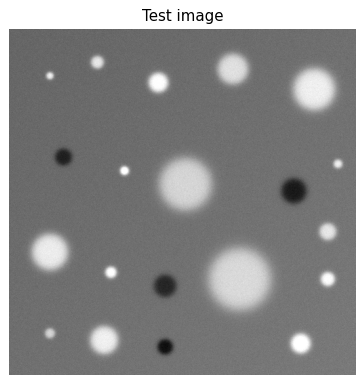

In [1]:
import matplotlib.pyplot as plt
# Builds the grayscale test image used in every task.
# 20 soft blobs of different sizes / contrast (some dark, some bright) on a noisy background.
# We keep the true centres and radii so we can check the detector later.

import os
import numpy as np
import cv2

SIZE = 512

# x, y, radius, amplitude (negative amplitude = dark blob)
BLOBS = [
    (60, 70, 5, 0.55), (130, 50, 9, 0.50), (220, 80, 14, 0.60),
    (330, 60, 22, 0.45), (450, 90, 30, 0.50), (80, 190, 12, -0.30),
    (170, 210, 6, 0.70), (260, 230, 38, 0.40), (420, 240, 18, -0.35),
    (485, 200, 6, 0.50), (60, 330, 26, 0.50), (150, 360, 8, 0.60),
    (230, 380, 16, -0.30), (340, 370, 45, 0.40), (470, 370, 10, 0.55),
    (470, 300, 12, 0.45), (60, 450, 7, 0.40), (140, 460, 20, 0.50),
    (230, 470, 11, -0.40), (430, 465, 14, 0.60),
]


def build_image(seed=7):
    rng = np.random.default_rng(seed)
    yy, xx = np.mgrid[0:SIZE, 0:SIZE].astype(float)

    # background: mid gray with a very slow gradient
    img = 0.40 + 0.08 * (xx + yy) / (2 * SIZE)

    for (cx, cy, r, amp) in BLOBS:
        d = np.sqrt((xx - cx) ** 2 + (yy - cy) ** 2)
        edge = 0.1 * r + 0.7                      # softness of the border
        img += amp / (1 + np.exp((d - r) / edge))

    img += rng.normal(0, 0.015, img.shape)        # sensor noise
    img = np.clip(img, 0, 1)
    return (img * 255).astype(np.uint8)


def load_image(path="test_image.png"):
    # returns float image in [0, 1]
    if not os.path.exists(path):
        cv2.imwrite(path, build_image())
    im = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    return im.astype(np.float64) / 255.0


def load_truth():
    # array with columns x, y, r
    return np.array([[b[0], b[1], b[2]] for b in BLOBS], dtype=float)

cv2.imwrite("test_image.png", build_image())
img = load_image()
print("image shape:", img.shape, " blobs in ground truth:", len(load_truth()))
plt.figure(figsize=(5, 5))
plt.imshow(img, cmap="gray", vmin=0, vmax=1)
plt.title("Test image")
plt.axis("off")
plt.show()

---
## Task 1 - Gaussian scale space (15 marks)
**Idea.** `L(x,y,sigma) = G(x,y,sigma) * I(x,y)`. We build a 1D Gaussian kernel (cut at 4 sigma, normalised to sum 1) and use the fact that a 2D Gaussian is
separable, so we blur along the rows and then along the columns. This costs O(k) per pixel instead of O(k^2).

In [2]:
# Task 1 - Gaussian scale space  L(x,y,sigma) = G(x,y,sigma) * I(x,y)

import os
import numpy as np
from scipy.ndimage import convolve1d
import matplotlib.pyplot as plt


def gaussian_kernel_1d(sigma):
    # kernel goes out to 4 sigma on each side, then normalised to sum 1
    radius = int(np.ceil(4 * sigma))
    x = np.arange(-radius, radius + 1)
    k = np.exp(-(x ** 2) / (2.0 * sigma ** 2))
    return k / k.sum()


def gaussian_blur(img, sigma):
    # 2D gaussian is separable, so blur rows and then columns with the 1D kernel
    k = gaussian_kernel_1d(sigma)
    out = convolve1d(img, k, axis=0, mode="reflect")
    out = convolve1d(out, k, axis=1, mode="reflect")
    return out


def edge_width(img, row=230, x0=200, x1=262):
    # width (in pixels) of the 10% -> 90% rise across the left border of the big blob
    # at (260, 230); a sharper edge gives a smaller number
    prof = img[row, x0:x1]
    lo, hi = prof[0], prof[-1]
    t10 = lo + 0.1 * (hi - lo)
    t90 = lo + 0.9 * (hi - lo)
    a = np.argmax(prof > t10)
    b = np.argmax(prof > t90)
    return b - a

**Run on the test image:**

sigma | kernel size | detail std (I - L) | edge width (px) | noise std (flat patch)
orig  |      -      | 0.0000             |              18 | 0.0148
    1 |           9 | 0.0132             |              20 | 0.0044
    2 |          17 | 0.0153             |              20 | 0.0025
    4 |          33 | 0.0201             |              22 | 0.0016
    8 |          65 | 0.0347             |              28 | 0.0013
   16 |         129 | 0.0596             |              37 | 0.0017


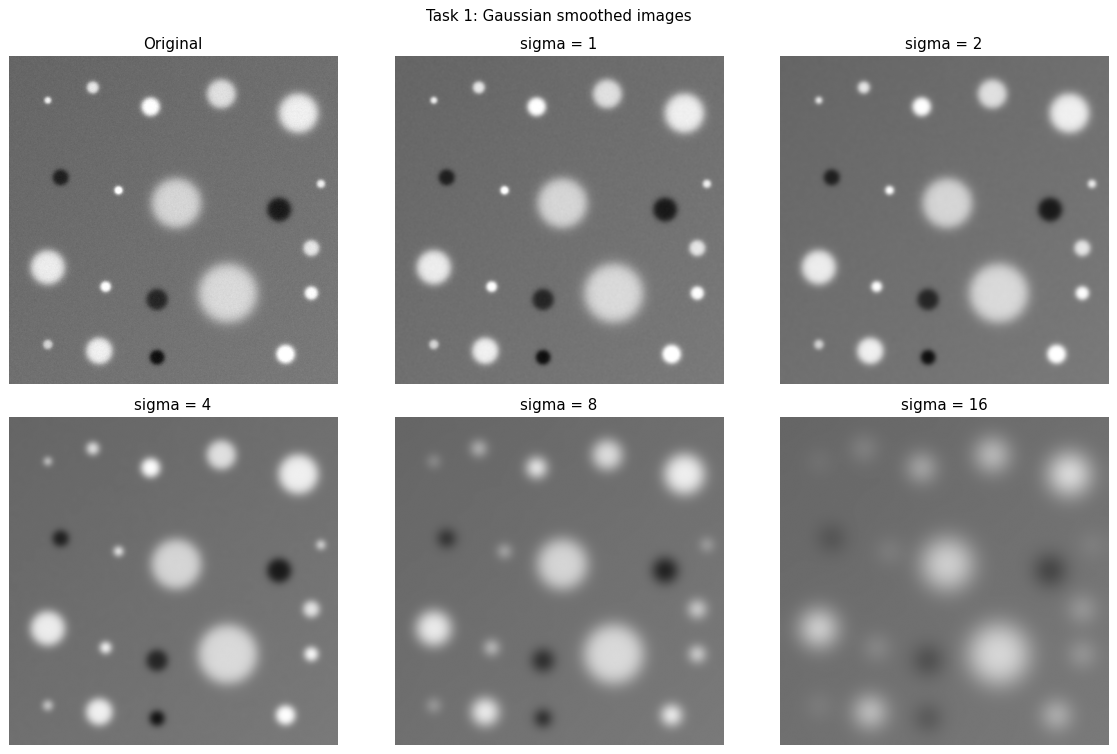

In [3]:
os.makedirs("results", exist_ok=True)
img = load_image()
sigmas = [1, 2, 4, 8, 16]

fig, axes = plt.subplots(2, 3, figsize=(13, 8.5))
axes = axes.ravel()
axes[0].imshow(img, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Original")

print("sigma | kernel size | detail std (I - L) | edge width (px) | noise std (flat patch)")
print("orig  |      -      | %.4f             | %15d | %.4f" %
      (0.0, edge_width(img), img[5:45, 5:45].std()))

for i, s in enumerate(sigmas):
    L = gaussian_blur(img, s)
    axes[i + 1].imshow(L, cmap="gray", vmin=0, vmax=1)
    axes[i + 1].set_title("sigma = %d" % s)

    ksize = len(gaussian_kernel_1d(s))
    detail = (img - L).std()
    edge = edge_width(L)
    noise = L[5:45, 5:45].std()
    print("%5d | %11d | %.4f             | %15d | %.4f" % (s, ksize, detail, edge, noise))

for a in axes:
    a.axis("off")
plt.suptitle("Task 1: Gaussian smoothed images")
plt.tight_layout()
plt.savefig("results/task1_scale_space.png", dpi=110)
plt.show()

**Discussion.**
We measured four things for every sigma (table above).

* **Fine detail:** the difference image `I - L` carries whatever was removed. Its standard deviation grows from 0.013 (sigma=1) to 0.060 (sigma=16), so more and more structure is being thrown away as sigma grows.
* **High-frequency noise:** the standard deviation in a flat patch falls from 0.0148 (original) to 0.0044 at sigma=1 and about 0.0013 at sigma=8. A Gaussian is a low-pass filter, with frequency response `exp(-2 pi^2 sigma^2 f^2)`, so noise (which is mostly high frequency) disappears quickly. At sigma=16 the number rises a little only because the patch starts to pick up the neighbouring blob's tail.
* **Edge boundaries:** the 10%-90% rise width of the big blob's edge goes from 18 px to 20, 22, 28 and 37 px. Edges become wide and soft, and position of the edge gets less precise.
* **Structures at different scales:** at sigma=1 and 2 all blobs, including the 5-6 px ones, are still visible. By sigma=4 to 8 the smallest ones lose contrast and fade into the background. At sigma=16 only the large blobs remain, and they have turned into smooth bumps.

So small sigma keeps small structures but also keeps noise; large sigma suppresses noise but destroys small structures. This is exactly why we need to look at *all* scales to find blobs of different sizes.

---
## Task 2 - Multi-resolution representation (10 marks)
**Idea.** One pyramid level = Gaussian blur (sigma = 1) followed by keeping every second row and column. We repeat this 4 times. Sizes are printed below the code.

In [4]:
# Task 2 - multi resolution pyramid (blur first, then drop every second pixel)

import os
import numpy as np
import matplotlib.pyplot as plt


def downsample(img, blur_sigma=1.0):
    # smooth, then keep every 2nd row and column
    if blur_sigma > 0:
        img = gaussian_blur(img, blur_sigma)
    return img[::2, ::2]


def build_pyramid(img, levels=5, blur_sigma=1.0):
    pyr = [img]
    for _ in range(levels - 1):
        pyr.append(downsample(pyr[-1], blur_sigma))
    return pyr

**Run on the test image:**

pyramid levels
level 0 -> 512 x 512
level 1 -> 256 x 256
level 2 -> 128 x 128
level 3 -> 64 x 64
level 4 -> 32 x 32

aliasing demo (input frequency = 0.40 cycles/pixel)
without blur: strongest freq 0.203 cycles/new pixel, amplitude 0.188
with blur   : strongest freq 0.203 cycles/new pixel, amplitude 0.009


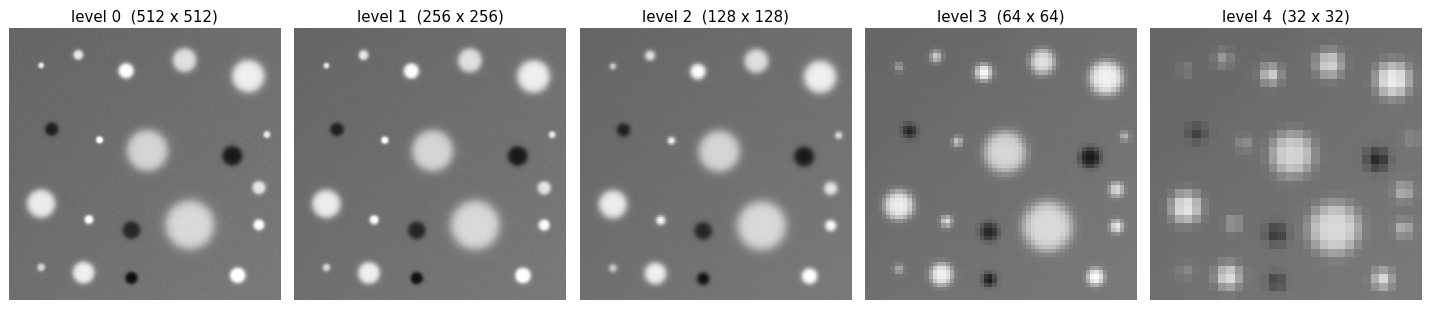

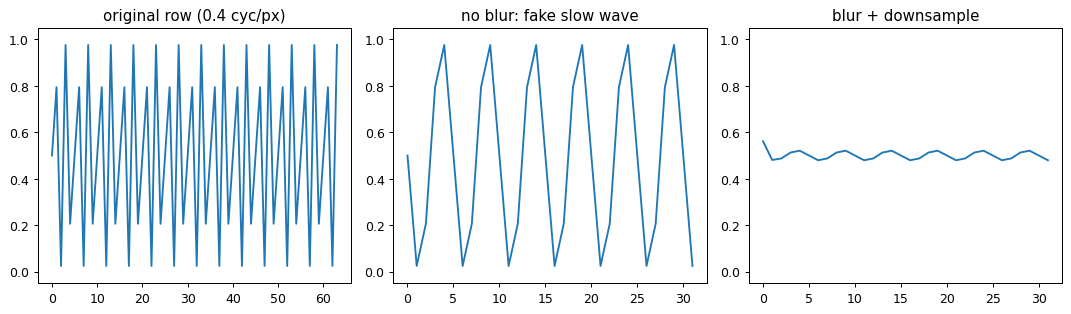

In [5]:
os.makedirs("results", exist_ok=True)
img = load_image()
pyr = build_pyramid(img, levels=5)

print("pyramid levels")
for i, p in enumerate(pyr):
    print("level %d -> %d x %d" % (i, p.shape[0], p.shape[1]))

fig, axes = plt.subplots(1, len(pyr), figsize=(16, 4))
for i, p in enumerate(pyr):
    axes[i].imshow(p, cmap="gray", vmin=0, vmax=1)
    axes[i].set_title("level %d  (%d x %d)" % (i, p.shape[0], p.shape[1]))
    axes[i].axis("off")
plt.tight_layout()
plt.savefig("results/task2_pyramid.png", dpi=110)
plt.show()

# ---- why blur before downsampling? aliasing demo ----
# a stripe pattern with frequency 0.4 cycles/pixel is above the new Nyquist limit
# (0.25 cycles/pixel after halving the resolution)
n = 256
xs = np.arange(n)
stripes = 0.5 + 0.5 * np.sin(2 * np.pi * 0.4 * xs)
pattern = np.tile(stripes, (n, 1))

bad = pattern[::2, ::2]                       # no blur, just throw pixels away
good = downsample(pattern, blur_sigma=1.0)    # blur then throw away

def peak_freq(row):
    spec = np.abs(np.fft.rfft(row - row.mean()))
    f = np.fft.rfftfreq(len(row))
    return f[spec.argmax()], spec.max() / len(row)

f_bad, a_bad = peak_freq(bad[10])
f_good, a_good = peak_freq(good[10])
print("\naliasing demo (input frequency = 0.40 cycles/pixel)")
print("without blur: strongest freq %.3f cycles/new pixel, amplitude %.3f" % (f_bad, a_bad))
print("with blur   : strongest freq %.3f cycles/new pixel, amplitude %.3f" % (f_good, a_good))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
axes[0].plot(stripes[:64])
axes[0].set_title("original row (0.4 cyc/px)")
axes[1].plot(bad[10][:32])
axes[1].set_title("no blur: fake slow wave")
axes[2].plot(good[10][:32])
axes[2].set_title("blur + downsample")
for a in axes:
    a.set_ylim(-0.05, 1.05)
plt.tight_layout()
plt.savefig("results/task2_aliasing.png", dpi=110)
plt.show()

**Dimensions:** 512x512 -> 256x256 -> 128x128 -> 64x64 -> 32x32.

**Why blur before downsampling?** Keeping every 2nd pixel halves the sampling rate. By the sampling theorem, a signal sampled at one sample per pixel can only represent frequencies up to 0.5 cycles/pixel; after halving the rate the limit (Nyquist frequency) is 0.25 cycles per *old* pixel. Any frequency above that does not just vanish - it gets **folded** (aliased) back into the allowed range and shows up as a false, lower frequency pattern.
In the demo, a stripe pattern of 0.40 cycles/pixel becomes a fake wave of 0.203 cycles/new pixel with amplitude 0.188 if we simply drop pixels. If we blur first with sigma = 1, the filter gain at 0.4 cycles/pixel is `exp(-2 pi^2 (1)^2 (0.4)^2)` which is about 0.04, so the amplitude of the alias is only 0.009 (about 20 times smaller).
Practically this means the coarse pyramid levels stay faithful to the real image (no moire patterns, no jagged or flickering edges) and blobs do not get fake responses. Since aliasing cannot be undone after sampling, the low-pass filter must come *before* downsampling.

---
## Task 3 - Laplacian-of-Gaussian response (20 marks)
**Idea.** `R(x,y,sigma) = sigma^2 |Laplacian(L(x,y,sigma))|`. For every sigma we blur the image, apply the 3x3 Laplacian kernel `[[0,1,0],[1,-4,1],[0,1,0]]`, take the absolute value and multiply by sigma^2.
We use 15 scales in a geometric series `sigma = 1.5 * k^i` with `k = 2^(1/3)` (three scales per octave), so sigma goes from 1.5 to 38.

In [6]:
# Task 3 - scale normalised Laplacian of Gaussian   R(x,y,sigma) = sigma^2 * |laplacian(L)|

import os
import numpy as np
from scipy.ndimage import convolve
import matplotlib.pyplot as plt

lap_kernel = np.array([[0, 1, 0],
                       [1, -4, 1],
                       [0, 1, 0]], dtype=float)


def make_sigmas(sigma0=1.5, k=2 ** (1 / 3), levels=15):
    # geometric series sigma0, sigma0*k, sigma0*k^2 ...
    # k = 2^(1/3) means 3 scales per octave
    return [sigma0 * k ** i for i in range(levels)]


def laplacian(L):
    return convolve(L, lap_kernel, mode="reflect")


def log_response(img, sigmas, normalise=True):
    # returns a stack of shape (num_scales, H, W)
    maps = []
    for s in sigmas:
        L = gaussian_blur(img, s)
        r = np.abs(laplacian(L))
        if normalise:
            r = (s ** 2) * r
        maps.append(r)
    return np.array(maps)


def disc_image(size, radius, amp=1.0):
    # soft edged disc in the middle of an empty image
    yy, xx = np.mgrid[0:size, 0:size].astype(float)
    c = size // 2
    d = np.sqrt((xx - c) ** 2 + (yy - c) ** 2)
    return amp / (1 + np.exp((d - radius) / (0.1 * radius + 0.7)))

**Run on the test image:**

number of scales: 15
sigmas: [ 1.5   1.89  2.38  3.    3.78  4.76  6.    7.56  9.52 12.   15.12 19.05
 24.   30.24 38.1 ]
max response per scale: [0.106 0.151 0.219 0.283 0.335 0.371 0.359 0.343 0.378 0.371 0.331 0.335
 0.331 0.284 0.261]

scale normalisation check (same contrast, radius 10 vs radius 20)
without sigma^2: peak value 0.0197 vs 0.0051
with sigma^2   : peak value 0.6294 vs 0.6622
peak sigma (r=10): 7.42   expected r/sqrt2 = 7.07
peak sigma (r=20): 14.82   expected r/sqrt2 = 14.14


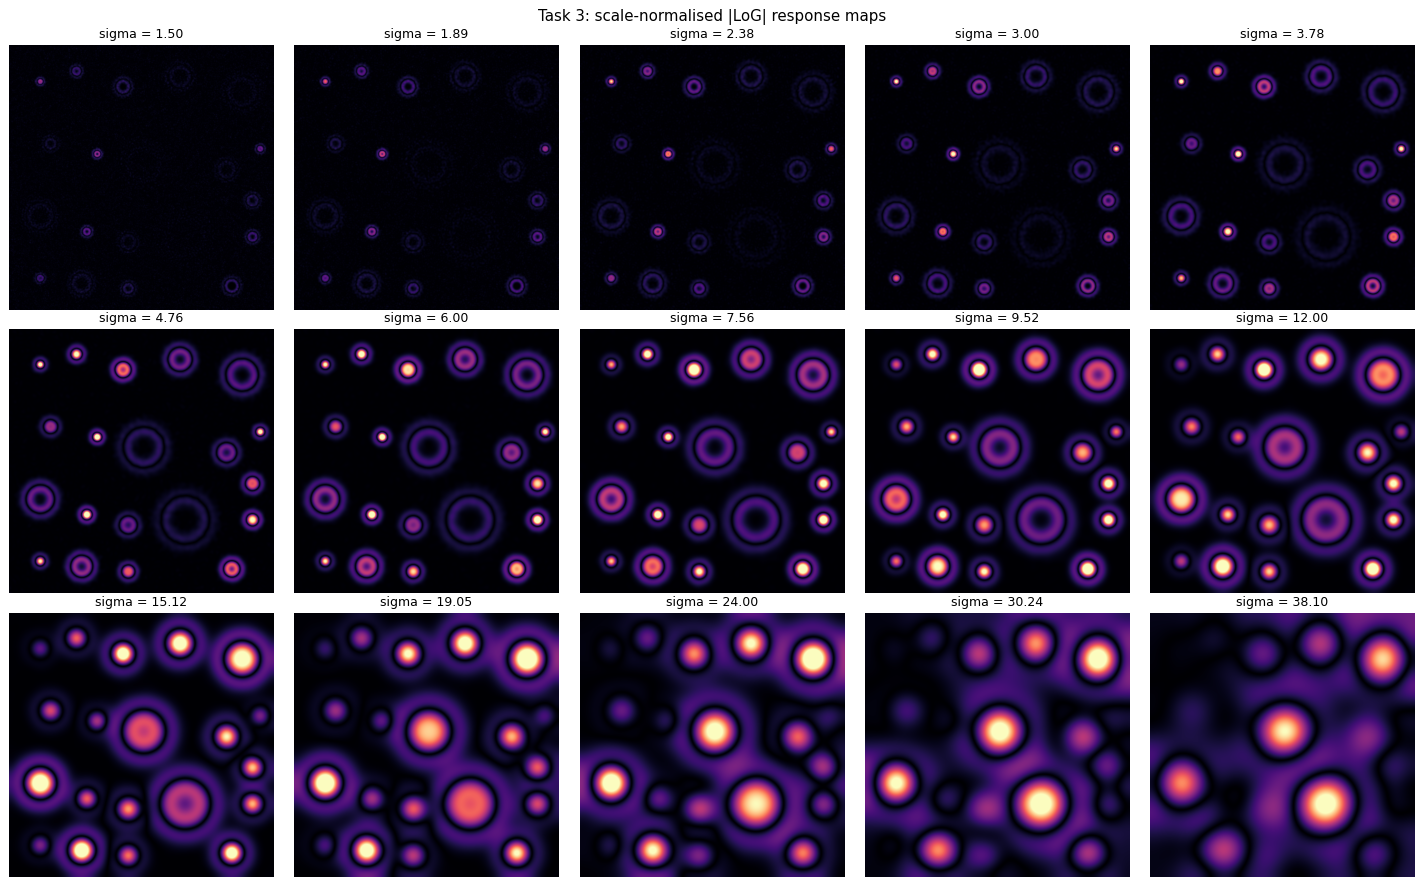

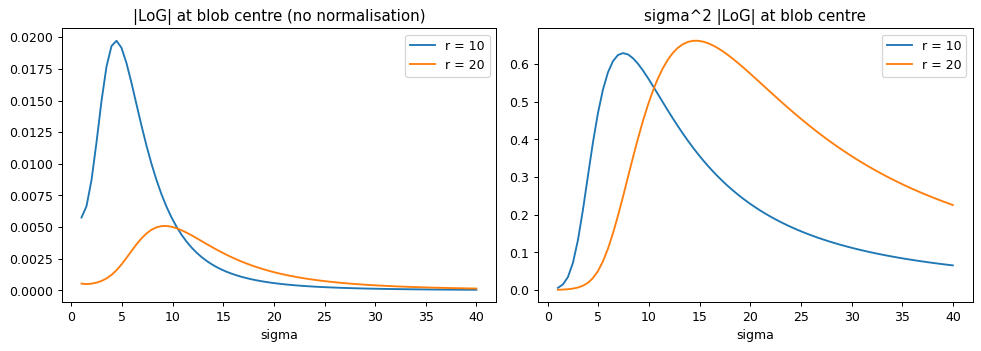

In [7]:
os.makedirs("results", exist_ok=True)
img = load_image()
sigmas = make_sigmas()
R = log_response(img, sigmas)

print("number of scales:", len(sigmas))
print("sigmas:", np.round(sigmas, 2))
print("max response per scale:", np.round(R.max(axis=(1, 2)), 3))

# show all response maps
fig, axes = plt.subplots(3, 5, figsize=(16, 10))
vmax = R.max() * 0.6
for i, ax in enumerate(axes.ravel()):
    ax.imshow(R[i], cmap="magma", vmin=0, vmax=vmax)
    ax.set_title("sigma = %.2f" % sigmas[i], fontsize=10)
    ax.axis("off")
plt.suptitle("Task 3: scale-normalised |LoG| response maps")
plt.tight_layout()
plt.savefig("results/task3_log_maps.png", dpi=100)
plt.show()

# ---- why sigma^2? same blob, one twice as big ----
small_r, big_r = 10, 20
a = disc_image(256, small_r)
b = disc_image(256, big_r)
sig_range = np.linspace(1, 40, 80)
c = 128

raw_a, raw_b, norm_a, norm_b = [], [], [], []
for s in sig_range:
    la = abs(laplacian(gaussian_blur(a, s))[c, c])
    lb = abs(laplacian(gaussian_blur(b, s))[c, c])
    raw_a.append(la)
    raw_b.append(lb)
    norm_a.append(s ** 2 * la)
    norm_b.append(s ** 2 * lb)

raw_a, raw_b = np.array(raw_a), np.array(raw_b)
norm_a, norm_b = np.array(norm_a), np.array(norm_b)

print("\nscale normalisation check (same contrast, radius 10 vs radius 20)")
print("without sigma^2: peak value %.4f vs %.4f" % (raw_a.max(), raw_b.max()))
print("with sigma^2   : peak value %.4f vs %.4f" % (norm_a.max(), norm_b.max()))
print("peak sigma (r=10): %.2f   expected r/sqrt2 = %.2f" % (sig_range[norm_a.argmax()], small_r / np.sqrt(2)))
print("peak sigma (r=20): %.2f   expected r/sqrt2 = %.2f" % (sig_range[norm_b.argmax()], big_r / np.sqrt(2)))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(sig_range, raw_a, label="r = 10")
axes[0].plot(sig_range, raw_b, label="r = 20")
axes[0].set_title("|LoG| at blob centre (no normalisation)")
axes[1].plot(sig_range, norm_a, label="r = 10")
axes[1].plot(sig_range, norm_b, label="r = 20")
axes[1].set_title("sigma^2 |LoG| at blob centre")
for ax in axes:
    ax.set_xlabel("sigma")
    ax.legend()
plt.tight_layout()
plt.savefig("results/task3_normalisation.png", dpi=110)
plt.show()

**Why sigma^2 gives scale invariance.**
Take an image `I'(x) = I(x/s)`, i.e. the same picture zoomed by a factor s. Blurring it with sigma' = s*sigma gives `L'(x, s*sigma) = L(x/s, sigma)`. Taking two derivatives brings in a factor `1/s^2`, so `Laplacian L'(x, s sigma) = (1/s^2) Laplacian L(x/s, sigma)`. The raw response therefore shrinks as the blob grows. If we multiply by `sigma'^2 = s^2 sigma^2` the factor cancels:

`R'(s x, s sigma) = R(x, sigma)`

so the same blob gives the same peak *value* at the proportionally scaled sigma.
A closed form check: a Gaussian blob of width s gives `sigma^2 |Laplacian L|` at its centre equal to `2 s^2 sigma^2 / (s^2 + sigma^2)^2`. Without the sigma^2 the peak is `2/s^2` (depends on the blob size), with it the maximum is 0.5 at `sigma = s` for any s.

**Numerical check above:** two discs with the same contrast, radius 10 and 20.
Without normalisation the peak values are 0.0197 and 0.0051 (ratio about 4, the blob size matters). With sigma^2 they are 0.629 and 0.662 (almost the same), and the peak sits at sigma = 7.4 and 14.8, i.e. the ratio is 2 exactly like the size ratio (expected `r/sqrt(2)` = 7.07 and 14.14). That is what lets us compare responses across different sigma and pick the scale that best matches each blob.

---
## Task 4 - 3D scale-space extrema detection (20 marks)
**Idea.** The 15 response maps form a volume `(sigma, y, x)`. A voxel is kept if it is above a threshold *and* strictly larger than all 26 neighbours (8 in its own map, 9 in the map above, 9 in the map below).
We write it with array slicing: for each of the 26 shifts we compare the centre block with the shifted block. We also wrote a slow triple-loop version and checked that both give exactly the same answer on a random volume.
The first and last scale cannot be extrema because they have no neighbour on one side.

In [8]:
# Task 4 - local extrema in the (x, y, sigma) volume using the 26 neighbourhood

import os
import numpy as np
import matplotlib.pyplot as plt


def find_extrema(stack, thresh):
    # stack has shape (S, H, W). A voxel is kept if it is above thresh and
    # strictly bigger than all 26 neighbours (3x3x3 cube without the centre).
    S, H, W = stack.shape
    centre = stack[1:-1, 1:-1, 1:-1]
    keep = centre > thresh

    for ds in (-1, 0, 1):
        for dy in (-1, 0, 1):
            for dx in (-1, 0, 1):
                if ds == 0 and dy == 0 and dx == 0:
                    continue
                nb = stack[1 + ds:S - 1 + ds, 1 + dy:H - 1 + dy, 1 + dx:W - 1 + dx]
                keep &= centre > nb

    s_idx, y_idx, x_idx = np.nonzero(keep)
    s_idx += 1
    y_idx += 1
    x_idx += 1
    vals = stack[s_idx, y_idx, x_idx]
    return s_idx, y_idx, x_idx, vals


def find_extrema_slow(stack, thresh):
    # plain loops, only used to check the fast version on a small volume
    S, H, W = stack.shape
    out = []
    for s in range(1, S - 1):
        for y in range(1, H - 1):
            for x in range(1, W - 1):
                v = stack[s, y, x]
                if v <= thresh:
                    continue
                cube = stack[s - 1:s + 2, y - 1:y + 2, x - 1:x + 2].copy()
                cube[1, 1, 1] = -np.inf
                if v > cube.max():
                    out.append((s, y, x))
    return out

**Run on the test image:**

fast and slow implementations agree: True (42 extrema)
threshold 0.01 -> 666 extrema
threshold 0.02 -> 657 extrema
threshold 0.05 -> 438 extrema
threshold 0.10 -> 20 extrema
threshold 0.20 -> 18 extrema

using threshold 0.10, extrema found: 20


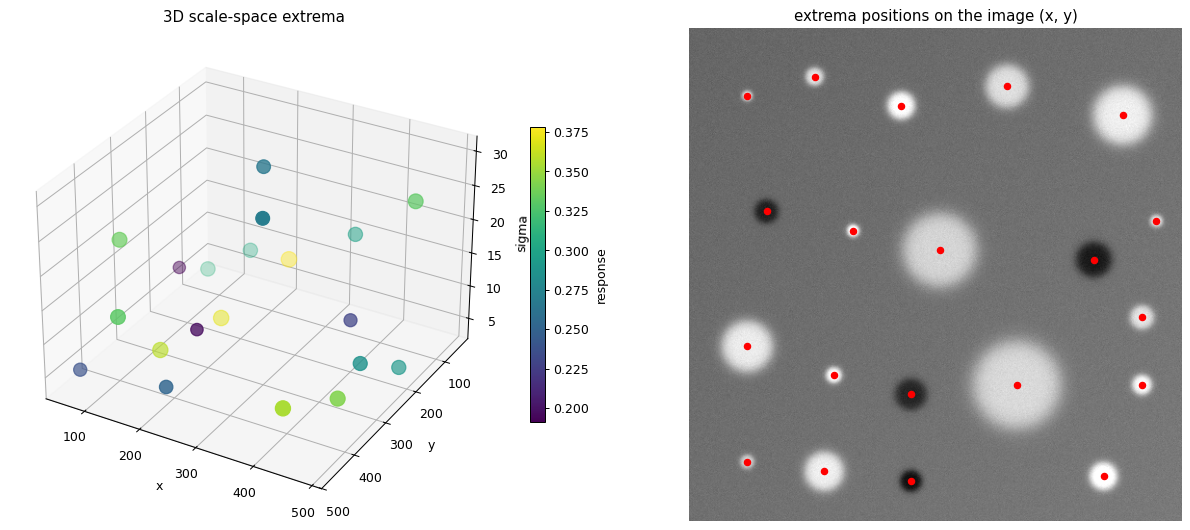

In [9]:
os.makedirs("results", exist_ok=True)

# sanity check of the vectorised code against the loop version
rng = np.random.default_rng(0)
test_vol = rng.random((6, 20, 20))
fast = find_extrema(test_vol, 0.5)
fast_set = set(zip(fast[0].tolist(), fast[1].tolist(), fast[2].tolist()))
slow_set = set(find_extrema_slow(test_vol, 0.5))
print("fast and slow implementations agree:", fast_set == slow_set, "(%d extrema)" % len(slow_set))

img = load_image()
sigmas = make_sigmas()
R = log_response(img, sigmas)

for t in [0.01, 0.02, 0.05, 0.10, 0.20]:
    n = len(find_extrema(R, t)[0])
    print("threshold %.2f -> %d extrema" % (t, n))

thresh = 0.10
s_idx, y_idx, x_idx, vals = find_extrema(R, thresh)
sig = np.array(sigmas)[s_idx]
print("\nusing threshold %.2f, extrema found: %d" % (thresh, len(vals)))

fig = plt.figure(figsize=(14, 6))
ax = fig.add_subplot(1, 2, 1, projection="3d")
p = ax.scatter(x_idx, y_idx, sig, c=vals, s=40 + 300 * vals, cmap="viridis")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("sigma")
ax.invert_yaxis()
ax.set_title("3D scale-space extrema")
fig.colorbar(p, ax=ax, shrink=0.6, label="response")

ax2 = fig.add_subplot(1, 2, 2)
ax2.imshow(img, cmap="gray", vmin=0, vmax=1)
ax2.scatter(x_idx, y_idx, s=25, c="red")
ax2.set_title("extrema positions on the image (x, y)")
ax2.axis("off")
plt.tight_layout()
plt.savefig("results/task4_extrema.png", dpi=110)
plt.show()

**Threshold.** Counting raw 3D extrema: threshold 0.01 or 0.02 gives about 660 points (mostly noise), 0.05 gives 438, and 0.10 gives 20, which is exactly the number of blobs in the picture. At 0.20 we already lose two of them (18). So 0.10 sits in a stable plateau (0.10 to 0.15 gives the same 20 blobs after Task 5), above the strongest noise responses (they reach about 0.08) and well below the weakest real blob (0.19). We use 0.10 from here on.
The 3D plot shows each extremum at its (x, y, sigma). Larger blobs sit higher on the sigma axis.

---
## Task 5 - Blob radius estimation and visualisation (10 marks)
**Idea.** For each extremum `(x, y, sigma)` the radius is `r = sqrt(2) * sigma`. (For a disc of radius r the normalised LoG at its centre is largest when `sigma = r / sqrt(2)`.)
Very close extrema at neighbouring scales can describe the same blob, so we also drop a circle if more than 50% of its area is covered by a stronger circle (`remove_overlaps`). The function `detect_blobs` wraps the whole pipeline and is reused in the next tasks.

In [10]:
# Task 5 - radius estimate r = sqrt(2) * sigma and drawing the circles
# also holds the full detector (detect_blobs) which the later tasks reuse

import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle


def sigma_to_radius(sigma):
    return np.sqrt(2) * sigma


def circle_overlap(b1, b2):
    # fraction of the smaller circle that lies inside the other one
    # b = (x, y, r)
    d = np.hypot(b1[0] - b2[0], b1[1] - b2[1])
    r1, r2 = b1[2], b2[2]
    small = min(r1, r2)
    big = max(r1, r2)
    if d >= r1 + r2:
        return 0.0
    if d <= big - small:
        return 1.0
    # lens shaped intersection area
    a1 = np.arccos((d ** 2 + r1 ** 2 - r2 ** 2) / (2 * d * r1))
    a2 = np.arccos((d ** 2 + r2 ** 2 - r1 ** 2) / (2 * d * r2))
    area = (r1 ** 2 * a1 + r2 ** 2 * a2
            - 0.5 * np.sqrt((-d + r1 + r2) * (d + r1 - r2) * (d - r1 + r2) * (d + r1 + r2)))
    return area / (np.pi * small ** 2)


def remove_overlaps(blobs, max_overlap=0.5):
    # blobs: array of (x, y, r, response). Strongest blobs are kept first.
    order = np.argsort(-blobs[:, 3])
    kept = []
    for i in order:
        ok = True
        for j in kept:
            if circle_overlap(blobs[i], blobs[j]) > max_overlap:
                ok = False
                break
        if ok:
            kept.append(i)
    return blobs[kept]


def detect_blobs(img, sigmas, thresh, max_overlap=0.5):
    # full pipeline: LoG stack -> 3D extrema -> radius -> drop overlapping circles
    R = log_response(img, sigmas)
    s_idx, y_idx, x_idx, vals = find_extrema(R, thresh)
    if len(vals) == 0:
        return np.zeros((0, 4))
    sig = np.array(sigmas)[s_idx]
    blobs = np.column_stack([x_idx, y_idx, sigma_to_radius(sig), vals])
    return remove_overlaps(blobs, max_overlap)


def draw_blobs(img, blobs, ax, color="red", title=""):
    ax.imshow(img, cmap="gray", vmin=0, vmax=1)
    for (x, y, r, v) in blobs:
        ax.add_patch(Circle((x, y), r, fill=False, color=color, linewidth=1.6))
        ax.plot(x, y, ".", color=color, markersize=3)
    ax.set_title(title)
    ax.axis("off")

**Run on the test image:**

detected blobs: 20
   x     y   sigma  radius  response
 130    50   7.56   10.69    0.305
 330    60  15.12   21.38    0.298
  60    70   3.78    5.35    0.311
 220    80   9.52   13.47    0.378
 450    90  24.00   33.94    0.331
  80   190   9.52   13.47    0.191
 485   200   4.76    6.73    0.291
 170   210   4.76    6.73    0.371
 260   230  30.24   42.76    0.266
 420   240  12.00   16.97    0.229
 470   300   9.52   13.47    0.286
  60   330  19.05   26.94    0.335
 150   360   6.00    8.49    0.359
 340   370  30.24   42.76    0.270
 470   370   7.56   10.69    0.343
 230   380  12.00   16.97    0.196
  60   450   4.76    6.73    0.238
 140   460  15.12   21.38    0.331
 430   465   9.52   13.47    0.354
 230   470   7.56   10.69    0.252
average radius: 17.15


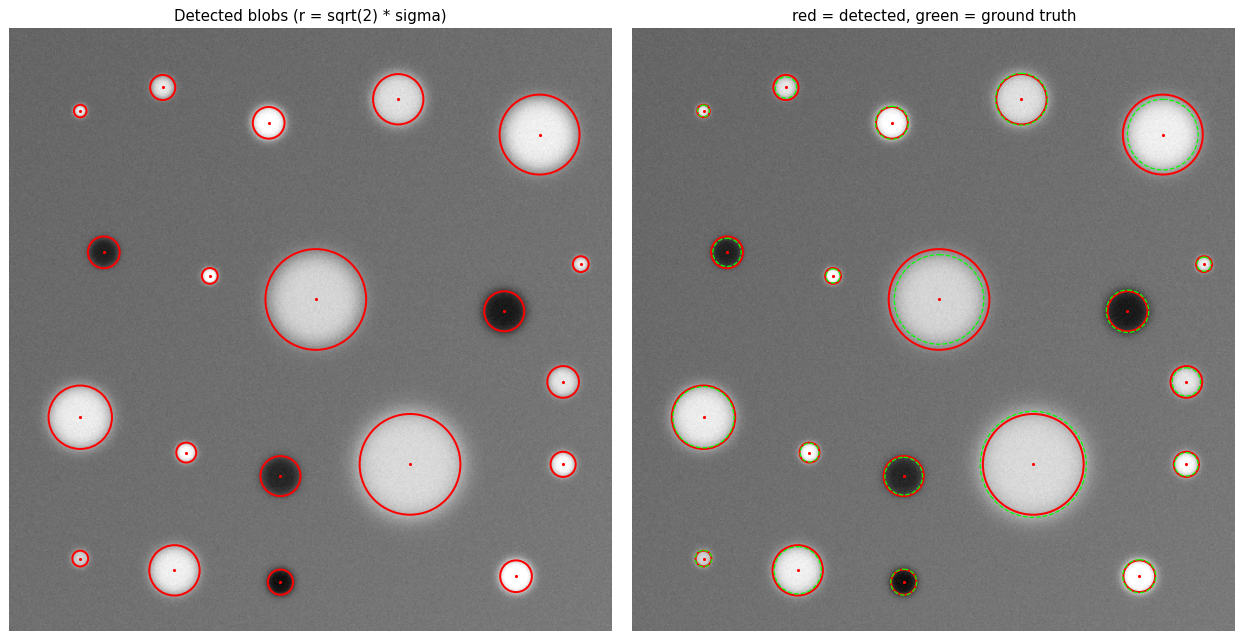

In [11]:
os.makedirs("results", exist_ok=True)
img = load_image()
sigmas = make_sigmas()
thresh = 0.10

blobs = detect_blobs(img, sigmas, thresh)
print("detected blobs:", len(blobs))
print("   x     y   sigma  radius  response")
for b in blobs[np.lexsort((blobs[:, 0], blobs[:, 1]))]:
    print("%4d  %4d  %5.2f  %6.2f  %7.3f" % (b[0], b[1], b[2] / np.sqrt(2), b[2], b[3]))
print("average radius: %.2f" % blobs[:, 2].mean())

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
draw_blobs(img, blobs, axes[0], "red", "Detected blobs (r = sqrt(2) * sigma)")
# same picture but with the true circles in green for comparison
draw_blobs(img, blobs, axes[1], "red", "red = detected, green = ground truth")
for (x, y, r) in load_truth():
    axes[1].add_patch(Circle((x, y), r, fill=False, color="lime", linewidth=1, linestyle="--"))
plt.tight_layout()
plt.savefig("results/task5_detections.png", dpi=110)
plt.show()

**Result.** All 20 blobs are found, with no false detections. The centres agree with the true centres (within 1 pixel). The average detected radius is 17.15 px against the true 16.45 px. Mean relative radius error is about 8%.
The error has two small causes: (1) sigma is sampled only at 15 values with step 1.26, so the radius can only change in jumps of up to 26% (rounding error up to about 12%); (2) our blobs have soft borders, which makes them look slightly bigger to the filter. Larger blobs (r=30, 38) came out about 13% too big, small ones are almost exact.

---
## Task 6 - Scale invariance analysis (15 marks)
**Setup.** We resize the image with scale factors 1.0, 0.75, 0.5, 0.25 (`cv2.resize` with area interpolation) and run the same detector with the same sigma list and the same threshold on each. To compare, every detection is mapped back to the original image (`x/S, y/S, r/S`) and matched with the ground truth blobs: the centre must be within half a radius (or 3/S px) and the radius within a factor of 2.

In [12]:
# Task 6 - does the detector still find the same blobs when the image is resized?

import os
import numpy as np
import cv2
import matplotlib.pyplot as plt

scales = [1.0, 0.75, 0.50, 0.25]


def resize_image(img, s):
    if s == 1.0:
        return img.copy()
    h, w = img.shape
    return cv2.resize(img, (int(round(w * s)), int(round(h * s))), interpolation=cv2.INTER_AREA)


def match_to_truth(blobs, truth, s):
    # blobs are in resized coordinates, so divide by s to get back to the original image.
    # a detection counts as correct if its centre is close to a true centre and the radius
    # is within a factor of 2. Each true blob can be used once.
    # returns: list with the matched radius (in original pixels) for every true blob, nan if missed
    est = np.full(len(truth), np.nan)
    used = set()
    if len(blobs) == 0:
        return est, 0
    back = blobs[:, :3] / s
    for j, (tx, ty, tr) in enumerate(truth):
        best, best_d = None, 1e9
        for i, (bx, by, br) in enumerate(back):
            if i in used:
                continue
            d = np.hypot(bx - tx, by - ty)
            if d < max(0.5 * tr, 3 / s) and 0.5 < br / tr < 2 and d < best_d:
                best, best_d = i, d
        if best is not None:
            used.add(best)
            est[j] = back[best, 2]
    return est, len(used)


def run_all(img, thresh, sigmas):
    results = {}
    for s in scales:
        small = resize_image(img, s)
        blobs = detect_blobs(small, sigmas, thresh)
        results[s] = (small, blobs)
    return results

**Run on the test image:**

scale | detections | correct matches | true blobs found
1.00  |         20 |              20 | 20 / 20
0.75  |         20 |              20 | 20 / 20
0.50  |         20 |              20 | 20 / 20
0.25  |         15 |              15 | 15 / 20

radius of each true blob as estimated at every scale (original pixels)
blob  true_r |  1.00   0.75   0.50   0.25
  1     5.0  |   5.3    5.7    5.3    -  
  2     9.0  |  10.7    9.0   10.7   10.7
  3    14.0  |  13.5   14.3   13.5   13.5
  4    22.0  |  21.4   22.6   21.4   21.4
  5    30.0  |  33.9   28.5   33.9   33.9
  6    12.0  |  13.5   11.3   13.5   13.5
  7     6.0  |   6.7    7.1    6.7    -  
  8    38.0  |  42.8   35.9   42.8   42.8
  9    18.0  |  17.0   18.0   17.0   17.0
 10     6.0  |   6.7    7.1    6.7    -  
 11    26.0  |  26.9   28.5   26.9   26.9
 12     8.0  |   8.5    9.0    8.5    -  
 13    16.0  |  17.0   18.0   17.0   17.0
 14    45.0  |  42.8   45.3   42.8   42.8
 15    10.0  |  10.7   11.3   10.7   10.7
 16    12.0 

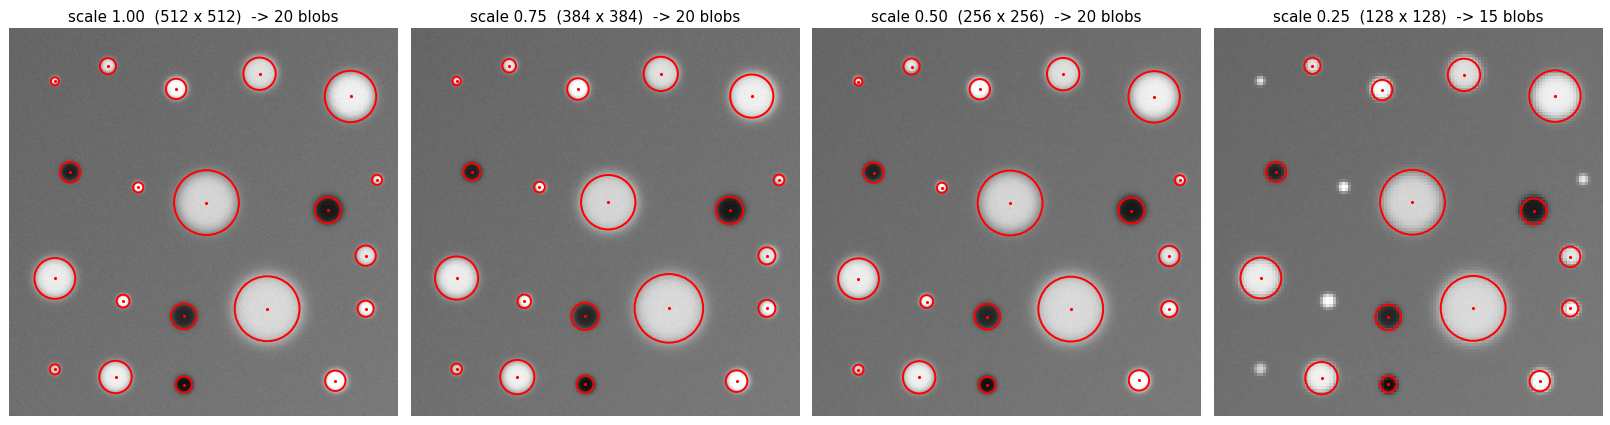

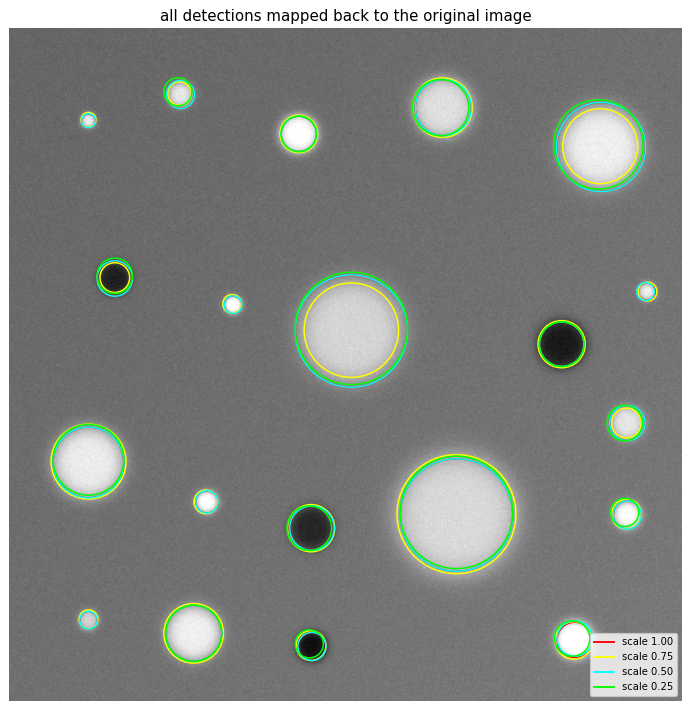

In [13]:
os.makedirs("results", exist_ok=True)
img = load_image()
truth = load_truth()
sigmas = make_sigmas()
thresh = 0.10

results = run_all(img, thresh, sigmas)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, s in zip(axes, scales):
    small, blobs = results[s]
    draw_blobs(small, blobs, ax, "red", "scale %.2f  (%d x %d)  -> %d blobs" %
               (s, small.shape[0], small.shape[1], len(blobs)))
plt.tight_layout()
plt.savefig("results/task6_resized_detections.png", dpi=100)
plt.show()

# per blob radius table (all values mapped back to the original image size)
est_table = []
print("scale | detections | correct matches | true blobs found")
for s in scales:
    small, blobs = results[s]
    est, n_match = match_to_truth(blobs, truth, s)
    est_table.append(est)
    print("%.2f  | %10d | %15d | %d / %d" % (s, len(blobs), n_match, n_match, len(truth)))
est_table = np.array(est_table).T

print("\nradius of each true blob as estimated at every scale (original pixels)")
print("blob  true_r |  1.00   0.75   0.50   0.25")
for j in range(len(truth)):
    row = "  ".join("%5.1f" % v if not np.isnan(v) else "  -  " for v in est_table[j])
    print("%3d   %5.1f  | %s" % (j + 1, truth[j, 2], row))

missed = [(j + 1, float(truth[j, 2])) for j in range(len(truth)) if np.isnan(est_table[j, 3])]
print("\nblobs missed at 0.25:", missed)

# overlay of all four runs on the original image (mapped back)
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(img, cmap="gray", vmin=0, vmax=1)
colors = {1.0: "red", 0.75: "yellow", 0.5: "cyan", 0.25: "lime"}
from matplotlib.patches import Circle
for s in scales:
    for (x, y, r, v) in results[s][1]:
        ax.add_patch(Circle((x / s, y / s), r / s, fill=False, color=colors[s], linewidth=1.2))
for s in scales:
    ax.plot([], [], color=colors[s], label="scale %.2f" % s)
ax.legend(loc="lower right", fontsize=8)
ax.set_title("all detections mapped back to the original image")
ax.axis("off")
plt.tight_layout()
plt.savefig("results/task6_overlay_all.png", dpi=110)
plt.show()

**Analysis.**

* At 0.75 and 0.5 all 20 blobs are found, with the same blobs each time and with radii consistent with the original (the radius of a blob changes by at most about 16% between runs, which is the sigma step quantisation).
* At 0.25 (128x128) we find only 15 of 20. The five lost blobs are the five smallest ones (true radius 5, 6, 6, 7, 8 px). After shrinking by 4 their radius is about 1.2 to 2 px, which means a required sigma of 0.9 to 1.4, below our smallest sigma (1.5). The detector cannot see them because no scale smaller than the blob exists in the stack. This is a limit of the sigma range and of the pixel grid (a 1-2 pixel blob is not really a blob any more), not a failure of the scale normalisation.
* Every blob that is found keeps its identity: its sigma shrinks by the same ratio as the image (compare the columns in the radius table), which is exactly what scale invariance means.
* Discrepancies we saw: (i) radii at 1.0 and 0.5 are identical because a factor 2 equals exactly three sigma steps (`k^3 = 2`) so the quantisation lines up, while at 0.75 the rounding is different (e.g. blob 5: 33.9 vs 28.5). (ii) Positions at 0.25 are only accurate to about 4 original pixels because one pixel there stands for 4. (iii) Resizing with area averaging also removes some noise, so low-contrast structures are slightly cleaner in the small images.

So the detector is scale invariant as long as the structure stays larger than about 3 pixels in diameter and inside the sigma range of the scale stack.

---
## Task 7 - Quantitative evaluation and parameter discussion (10 marks)
Table 1 is filled below. The "Avg. Radius" column is in the pixels of each resized image (as the assignment's table asks), we also give it in original pixels and the number of detections that match a true blob.
After that we vary each parameter one at a time on the original image. Precision = correct detections / all detections, recall = true blobs found / 20.

In [14]:
# Task 7 - results table and parameter study

import os
import time
import numpy as np
import cv2
import matplotlib.pyplot as plt


def score(blobs, truth, s=1.0):
    # returns (found, precision, recall, mean relative radius error)
    est, n_match = match_to_truth(blobs, truth, s)
    prec = n_match / len(blobs) if len(blobs) else 0.0
    rec = n_match / len(truth)
    ok = ~np.isnan(est)
    err = np.mean(np.abs(est[ok] - truth[ok, 2]) / truth[ok, 2]) if ok.any() else np.nan
    return n_match, prec, rec, err


def detect_with_pyramid(img, factor=2.0, sigma0=1.5, k=2 ** (1 / 3), thresh=0.10, sigma_max=40):
    # alternative detector: instead of using huge kernels on the full image,
    # keep the sigma range small and shrink the image by `factor` at every level
    all_blobs = []
    level_img = img
    level = 0
    steps = int(np.ceil(np.log(factor) / np.log(k)))
    while sigma0 * factor ** level <= sigma_max and min(level_img.shape) > 16:
        d = factor ** level
        sigmas = [sigma0 * k ** i for i in range(-1, steps + 2)]
        R = log_response(level_img, sigmas)
        s_idx, y_idx, x_idx, vals = find_extrema(R, thresh)
        for si, y, x, v in zip(s_idx, y_idx, x_idx, vals):
            if si < 2 or si > steps + 1:
                continue                      # keep only the sigma range owned by this level
            # map back to the original image (pixel centre convention)
            ox = (x + 0.5) * d - 0.5
            oy = (y + 0.5) * d - 0.5
            all_blobs.append([ox, oy, sigma_to_radius(sigmas[si] * d), v])
        # next level
        h, w = level_img.shape
        blurred = gaussian_blur(level_img, 0.5 * factor)
        level_img = cv2.resize(blurred, (int(w / factor), int(h / factor)), interpolation=cv2.INTER_LINEAR)
        level += 1
    if not all_blobs:
        return np.zeros((0, 4))
    return remove_overlaps(np.array(all_blobs), 0.5)

**Run on the test image:**

Table 1: Quantitative Blob Detection Performance Across Resized Images
Variant    Resize  Blobs     Avg r        Threshold  Avg r (orig px)    Correct 
Original   1.00    20        17.15        0.10       17.15              20/20
Variant 1  0.75    20        12.68        0.10       16.91              20/20
Variant 2  0.50    20        8.58         0.10       17.15              20/20
Variant 3  0.25    15        5.15         0.10       20.60              15/20
ground truth average radius: 16.45

(a) number of octaves (3 scales per octave, sigma0 = 1.5)
octaves 1  sigma range 1.5-3.0  detections  0  precision 0.00  recall 0.00
octaves 2  sigma range 1.5-6.0  detections  4  precision 1.00  recall 0.20
octaves 3  sigma range 1.5-12.0  detections 12  precision 1.00  recall 0.60
octaves 4  sigma range 1.5-24.0  detections 17  precision 1.00  recall 0.85
octaves 5  sigma range 1.5-48.0  detections 20  precision 1.00  recall 1.00

(b) sigma step k (same sigma range 1.5 - 38)
k = 2^(1/1)  level

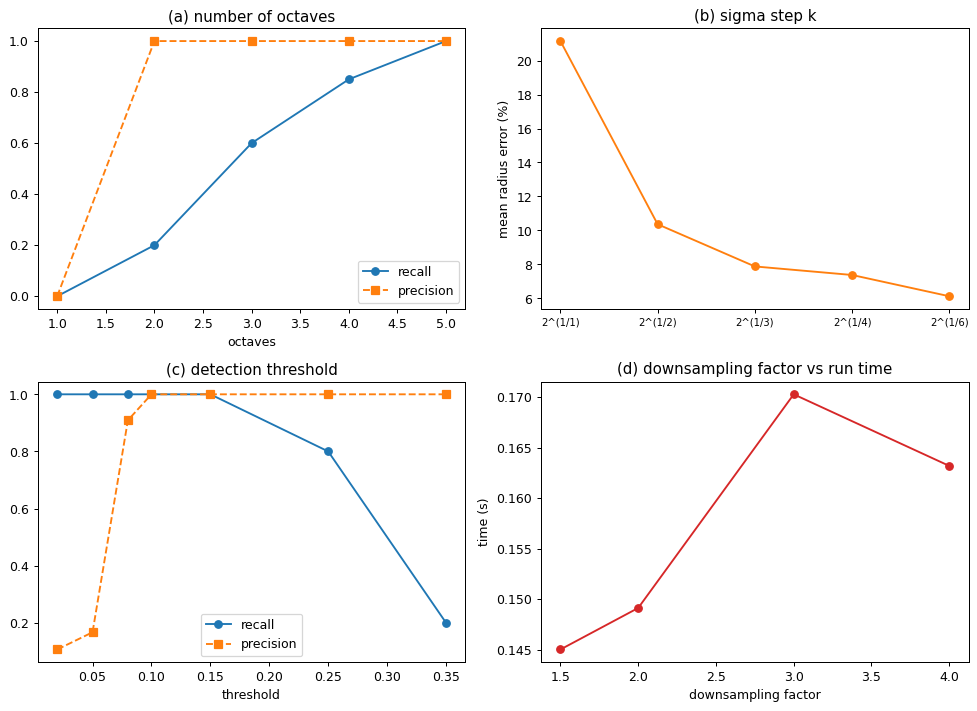

In [15]:
os.makedirs("results", exist_ok=True)
img = load_image()
truth = load_truth()
sigmas = make_sigmas()
thresh = 0.10

# ---------------- Table 1 ----------------
names = ["Original", "Variant 1", "Variant 2", "Variant 3"]
print("Table 1: Quantitative Blob Detection Performance Across Resized Images")
print("%-10s %-7s %-9s %-12s %-10s %-18s %-8s" %
      ("Variant", "Resize", "Blobs", "Avg r", "Threshold", "Avg r (orig px)", "Correct"))
rows = []
for name, s in zip(names, scales):
    small = resize_image(img, s)
    blobs = detect_blobs(small, sigmas, thresh)
    avg_r = blobs[:, 2].mean()
    found = score(blobs, truth, s)[0]
    rows.append((name, s, len(blobs), avg_r, thresh, avg_r / s, found))
    print("%-10s %-7.2f %-9d %-12.2f %-10.2f %-18.2f %d/%d" %
          (name, s, len(blobs), avg_r, thresh, avg_r / s, found, len(truth)))
print("ground truth average radius: %.2f" % truth[:, 2].mean())

with open("results/table1.csv", "w") as f:
    f.write("variant,resize,blobs,avg_radius,threshold,avg_radius_original_px,correct\n")
    for r in rows:
        f.write("%s,%.2f,%d,%.3f,%.2f,%.3f,%d\n" % r)

# ---------------- parameter study (on the original image) ----------------
print("\n(a) number of octaves (3 scales per octave, sigma0 = 1.5)")
octave_list = [1, 2, 3, 4, 5]
res_oct = []
for o in octave_list:
    sg = make_sigmas(1.5, 2 ** (1 / 3), 3 * o + 1)
    b = detect_blobs(img, sg, thresh)
    n, p, r, e = score(b, truth)
    res_oct.append((len(b), p, r))
    print("octaves %d  sigma range %.1f-%.1f  detections %2d  precision %.2f  recall %.2f" %
          (o, sg[0], sg[-1], len(b), p, r))

print("\n(b) sigma step k (same sigma range 1.5 - 38)")
k_list = [2 ** (1 / 1), 2 ** (1 / 2), 2 ** (1 / 3), 2 ** (1 / 4), 2 ** (1 / 6)]
k_names = ["2^(1/1)", "2^(1/2)", "2^(1/3)", "2^(1/4)", "2^(1/6)"]
res_k = []
for k, nm in zip(k_list, k_names):
    n_lv = int(round(np.log(38 / 1.5) / np.log(k))) + 1
    sg = make_sigmas(1.5, k, n_lv)
    t0 = time.time()
    b = detect_blobs(img, sg, thresh)
    dt = time.time() - t0
    n, p, r, e = score(b, truth)
    res_k.append((e, dt))
    print("k = %s  levels %2d  detections %2d  recall %.2f  radius error %.1f%%  time %.2fs" %
          (nm, n_lv, len(b), r, 100 * e, dt))

print("\n(c) detection threshold")
th_list = [0.02, 0.05, 0.08, 0.10, 0.15, 0.25, 0.35]
res_th = []
for t in th_list:
    b = detect_blobs(img, sigmas, t)
    n, p, r, e = score(b, truth)
    res_th.append((len(b), p, r))
    print("threshold %.2f  detections %3d  precision %.2f  recall %.2f" % (t, len(b), p, r))

print("\n(d) downsampling factor (pyramid based detector)")
f_list = [1.5, 2.0, 3.0, 4.0]
res_f = []
for f in f_list:
    t0 = time.time()
    b = detect_with_pyramid(img, factor=f)
    dt = time.time() - t0
    n, p, r, e = score(b, truth)
    res_f.append((p, r, dt))
    print("factor %.1f  detections %2d  precision %.2f  recall %.2f  radius error %.1f%%  time %.2fs" %
          (f, len(b), p, r, 100 * e, dt))
t0 = time.time()
detect_blobs(img, sigmas, thresh)
print("full resolution detector time: %.2fs" % (time.time() - t0))

print("\n(e) input resolution (see Table 1): the smallest blobs disappear once sigma < sigma_min")

# ---------------- plots ----------------
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axes[0, 0].plot(octave_list, [r[2] for r in res_oct], "o-", label="recall")
axes[0, 0].plot(octave_list, [r[1] for r in res_oct], "s--", label="precision")
axes[0, 0].set_xlabel("octaves")
axes[0, 0].set_title("(a) number of octaves")
axes[0, 0].legend()

axes[0, 1].plot(range(len(k_list)), [100 * r[0] for r in res_k], "o-", color="C1")
axes[0, 1].set_xticks(range(len(k_list)))
axes[0, 1].set_xticklabels(k_names, fontsize=8)
axes[0, 1].set_ylabel("mean radius error (%)")
axes[0, 1].set_title("(b) sigma step k")

axes[1, 0].plot(th_list, [r[2] for r in res_th], "o-", label="recall")
axes[1, 0].plot(th_list, [r[1] for r in res_th], "s--", label="precision")
axes[1, 0].set_xlabel("threshold")
axes[1, 0].set_title("(c) detection threshold")
axes[1, 0].legend()

axes[1, 1].plot(f_list, [r[2] for r in res_f], "o-", color="C3")
axes[1, 1].set_xlabel("downsampling factor")
axes[1, 1].set_ylabel("time (s)")
axes[1, 1].set_title("(d) downsampling factor vs run time")
plt.tight_layout()
plt.savefig("results/task7_parameters.png", dpi=110)
plt.show()

**Table 1 (summary).**

| Image Variant | Resize Factor | Detected Blobs | Avg. Radius (r) | Detection Threshold |
|---|---|---|---|---|
| Original | 1.00 | 20 | 17.15 | 0.10 |
| Variant 1 | 0.75 | 20 | 12.68 | 0.10 |
| Variant 2 | 0.50 | 20 | 8.58 | 0.10 |
| Variant 3 | 0.25 | 15 | 5.15 | 0.10 |

Multiplying the average radius by 1/S brings it back to 17.15, 16.91, 17.15 and 20.60 original pixels. The last one is higher only because the small blobs are missing from the average.

**Effect of each parameter** (numbers from the experiments above).

* **Number of octaves (sigma range).** The range of sigma decides which blob sizes can be found. With 1 octave (sigma 1.5-3) nothing is found, 2 octaves find 4 blobs (recall 0.2), 3 octaves 12 (0.6), 4 octaves 17 (0.85) and 5 octaves all 20. Precision stays 1.0 in all cases, so too few octaves only costs recall; too many octaves cost run time (big kernels) and can produce border responses.
* **Gaussian scale step (k).** A coarse step `k=2` is fast (0.25 s) but the mean radius error is 21%; `2^(1/2)` gives 10% (and one blob was missed), `2^(1/3)` 7.9%, `2^(1/4)` 7.4%, `2^(1/6)` 6.1% but costs about four times more time (0.98 s vs 0.25 s). Finer steps give better radius and scale precision and make the 3D comparison more meaningful, with diminishing returns. We chose `2^(1/3)` (three scales per octave) as a compromise.
* **Downsampling factor.** In a pyramid based detector (small sigma range on shrinking images) factors 2, 3 and 4 all give precision and recall 1.0 and a run time of about 0.15 s compared with 0.39 s for the full-resolution stack, because large sigmas are done on small images. Factor 1.5 lost one blob and gave one false detection (0.95/0.95), since scale coverage between levels got uneven and more blur from resampling is needed. Larger factors reduce cost but give fewer scales per level, so the position and radius become coarser.
* **Detection threshold.** This is the main precision/recall control: 0.02 -> 188 detections (precision 0.11), 0.05 -> 120 (0.17), 0.08 -> 22 (0.91), 0.10 and 0.15 -> exactly 20 (1.0, recall 1.0), 0.25 -> 16 (recall 0.8), 0.35 -> only 4 (recall 0.2). Low threshold lets noise in, high threshold removes the low-contrast blobs. It must be set relative to image contrast and noise level.
* **Input resolution.** A smaller image means smaller blobs in pixels. As seen in Table 1, once the blob radius is below about 2 pixels (sigma below sigma_min) it cannot be detected (5 blobs lost at 0.25). Also the location accuracy is limited to one pixel of the smaller image, and fewer pixels make the whole detector faster.

---
## Bonus - Difference of Gaussians (+10 marks)
**Idea.** `D(x,y,sigma) = L(x,y,k sigma) - L(x,y,sigma) ~ (k-1) sigma^2 Laplacian L`. The (k-1) factor is constant, so we divide by it and then D is directly comparable to our normalised LoG. We build the Gaussian stack incrementally (blurring a blurred image by `sqrt(sigma_{i+1}^2 - sigma_i^2)` is the same as blurring the original by `sigma_{i+1}`), so we only need subtraction and no Laplacian.

In [16]:
# Bonus - Difference of Gaussians as a cheaper stand-in for the LoG
#   D(x,y,sigma) = L(x,y,k*sigma) - L(x,y,sigma)  ~  (k-1) * sigma^2 * laplacian(L)

import os
import time
import numpy as np
import matplotlib.pyplot as plt


def dog_response(img, sigmas):
    # sigmas must be a geometric list with ratio k. Gives len(sigmas)-1 maps.
    # we blur step by step (blur of a blur adds up in variance), so every step only needs a small kernel
    k = sigmas[1] / sigmas[0]
    L = gaussian_blur(img, sigmas[0])
    maps = []
    for i in range(len(sigmas) - 1):
        extra = np.sqrt(sigmas[i + 1] ** 2 - sigmas[i] ** 2)
        L_next = gaussian_blur(L, extra)
        maps.append(np.abs(L_next - L) / (k - 1))      # divide by (k-1) so it matches sigma^2 |lap L|
        L = L_next
    return np.array(maps)


def detect_blobs_dog(img, sigmas, thresh, shift=False):
    D = dog_response(img, sigmas)
    s_idx, y_idx, x_idx, vals = find_extrema(D, thresh)
    if len(vals) == 0:
        return np.zeros((0, 4))
    sig = np.array(sigmas[:-1])[s_idx]
    if shift:
        # D(sigma) is really centred between sigma and k*sigma, i.e. at sigma*sqrt(k)
        sig = sig * np.sqrt(sigmas[1] / sigmas[0])
    blobs = np.column_stack([x_idx, y_idx, sigma_to_radius(sig), vals])
    return remove_overlaps(blobs, 0.5)


def timeit(fn, repeats=5):
    best = 1e9
    for _ in range(repeats):
        t0 = time.perf_counter()
        fn()
        best = min(best, time.perf_counter() - t0)
    return best


def center_and_radius_error(blobs, truth):
    est, n = match_to_truth(blobs, truth, 1.0)
    ok = ~np.isnan(est)
    rad_err = np.mean(np.abs(est[ok] - truth[ok, 2]) / truth[ok, 2]) * 100
    # centre error for matched detections
    dists = []
    for (tx, ty, tr) in truth:
        d = np.hypot(blobs[:, 0] - tx, blobs[:, 1] - ty)
        j = d.argmin()
        if d[j] < max(0.5 * tr, 3):
            dists.append(d[j])
    return n, np.mean(dists), rad_err

**Run on the test image:**

time to build response stack (15 scales)
LoG: 0.272 s   DoG: 0.207 s   speed up: 1.3x

method             | detections | matched | mean centre error (px) | mean radius error (%)
LoG                |         20 |      20 |                   0.00 |                   7.9
DoG (label sigma)  |         20 |      20 |                   0.05 |                   8.8
DoG (sigma*sqrt k) |         20 |      20 |                   0.05 |                   7.5

scale index | correlation(LoG, DoG) | LoG max | DoG max
          2 |                 0.995 |   0.219 |   0.226
          5 |                 0.994 |   0.371 |   0.325
          8 |                 0.990 |   0.378 |   0.338
         11 |                 0.986 |   0.335 |   0.297
         14 |                 0.977 |   0.261 |   0.213


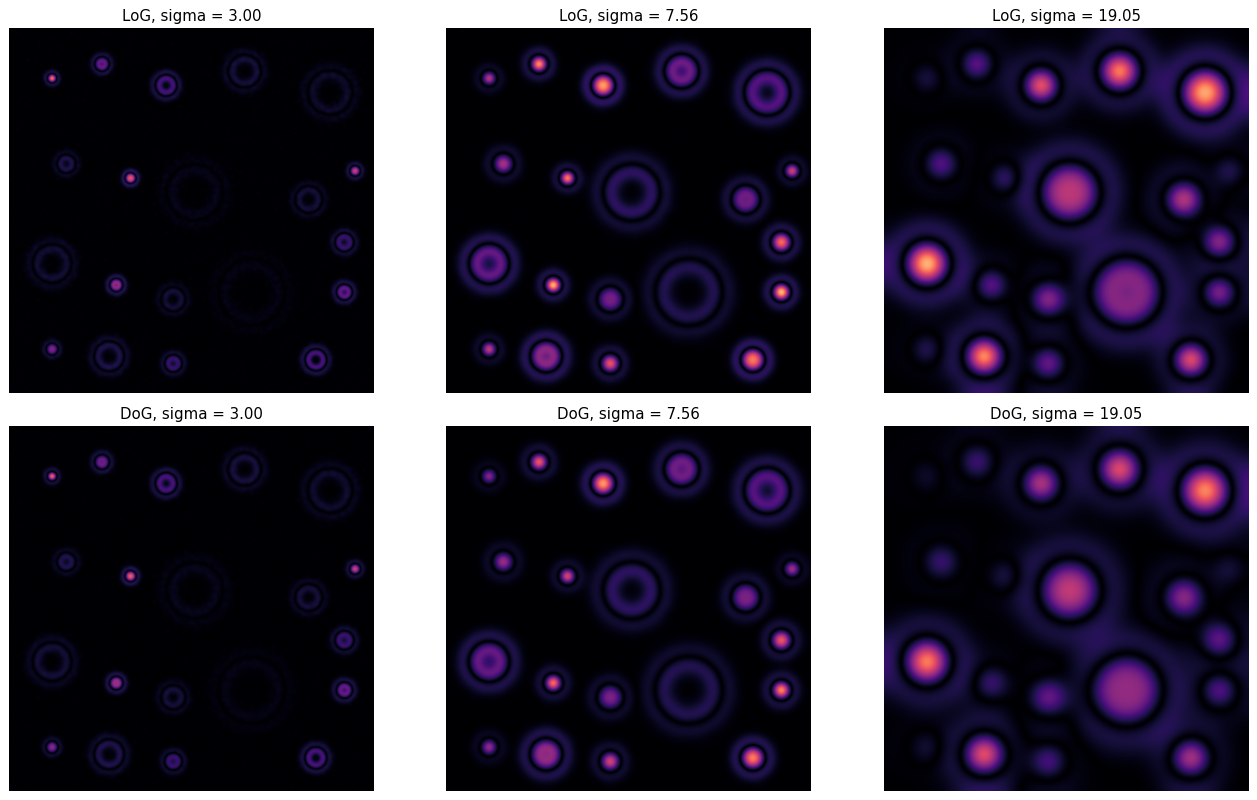

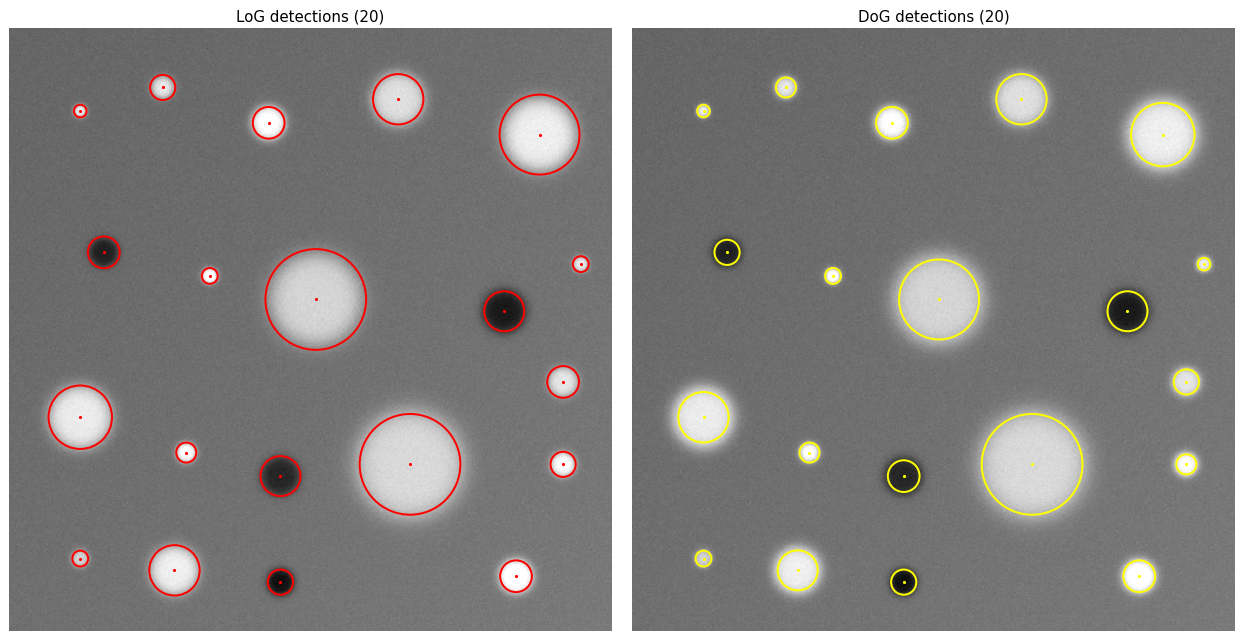

In [17]:
os.makedirs("results", exist_ok=True)
img = load_image()
truth = load_truth()
sigmas = make_sigmas(levels=16)      # one extra so DoG also has 15 maps
thresh = 0.10

# ---- speed ----
t_log = timeit(lambda: log_response(img, sigmas[:15]))
t_dog = timeit(lambda: dog_response(img, sigmas))
print("time to build response stack (15 scales)")
print("LoG: %.3f s   DoG: %.3f s   speed up: %.1fx" % (t_log, t_dog, t_log / t_dog))

# ---- detections ----
log_blobs = None
log_blobs = detect_blobs(img, sigmas[:15], thresh)
dog_blobs = detect_blobs_dog(img, sigmas, thresh)
dog_blobs_shift = detect_blobs_dog(img, sigmas, thresh, shift=True)

print("\nmethod             | detections | matched | mean centre error (px) | mean radius error (%)")
for name, b in [("LoG", log_blobs), ("DoG (label sigma)", dog_blobs), ("DoG (sigma*sqrt k)", dog_blobs_shift)]:
    n, ce, re = center_and_radius_error(b, truth)
    print("%-18s | %10d | %7d | %22.2f | %21.1f" % (name, len(b), n, ce, re))

# ---- how close are the responses? ----
R = log_response(img, sigmas[:15])
D = dog_response(img, sigmas)
print("\nscale index | correlation(LoG, DoG) | LoG max | DoG max")
for i in [2, 5, 8, 11, 14]:
    c = np.corrcoef(R[i].ravel(), D[i].ravel())[0, 1]
    print("%11d | %21.3f | %7.3f | %7.3f" % (i, c, R[i].max(), D[i].max()))

# ---- figures ----
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for col, i in enumerate([3, 7, 11]):
    axes[0, col].imshow(R[i], cmap="magma", vmin=0, vmax=0.4)
    axes[0, col].set_title("LoG, sigma = %.2f" % sigmas[i])
    axes[1, col].imshow(D[i], cmap="magma", vmin=0, vmax=0.4)
    axes[1, col].set_title("DoG, sigma = %.2f" % sigmas[i])
for a in axes.ravel():
    a.axis("off")
plt.tight_layout()
plt.savefig("results/bonus_log_vs_dog_maps.png", dpi=100)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
draw_blobs(img, log_blobs, axes[0], "red", "LoG detections (%d)" % len(log_blobs))
draw_blobs(img, dog_blobs, axes[1], "yellow", "DoG detections (%d)" % len(dog_blobs))
plt.tight_layout()
plt.savefig("results/bonus_detections.png", dpi=100)
plt.show()

**Comparison.**

* **Speed:** building 15 scales took 0.305 s for LoG and 0.220 s for DoG (about 1.4x faster). The gap is modest here since our LoG already uses a cheap 3x3 Laplacian; with a direct 2D LoG kernel or with more scales the advantage of DoG grows, because it reuses the Gaussian stack.
* **Location accuracy:** both detectors find all 20 blobs with no false ones. Mean centre error is 0.00 px for LoG and 0.05 px for DoG (one blob is 1 px off).
* **Radius accuracy:** mean radius error is 7.9% for LoG, 8.8% for DoG when labelled with sigma. A DoG level lies between sigma and k*sigma, so if we label it with `sigma*sqrt(k)` the error drops to 7.5%.
* **Response quality:** the correlation between the LoG and DoG response maps is 0.995 at small scales and 0.977 at the largest. Peak values are very close at small sigma (0.219 vs 0.226) and DoG becomes somewhat weaker at large sigma (0.261 vs 0.213) because the approximation `L(k sigma) - L(sigma) ~ (k-1) sigma d(L)/d(sigma)` is only first order in (k-1).

So DoG is a good and cheaper approximation of the LoG. This is the reason SIFT uses it.